In [8]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas version:", pd.__version__)
print("Setup OK")

pandas version: 2.2.3
Setup OK


In [9]:
import os
for root, dirs, files in os.walk("."):
    if "sample_data" in root or ".config" in root:
        continue
    for f in files:
        path = os.path.join(root, f)
        print(f"{path}  ->  {os.path.getsize(path)/1e6:.1f} MB")

./archive (1).zip  ->  2.9 MB


In [10]:
import zipfile, os

os.makedirs("data", exist_ok=True)
with zipfile.ZipFile("archive (1).zip") as z:
    print("Inside the zip:", z.namelist())
    z.extractall("data")

for root, dirs, files in os.walk("data"):
    for f in files:
        path = os.path.join(root, f)
        print(f"{path}  ->  {os.path.getsize(path)/1e6:.1f} MB")

Inside the zip: ['ipl_ball_by_ball.csv', 'ipl_matches.csv']
data/ipl_ball_by_ball.csv  ->  72.7 MB
data/ipl_matches.csv  ->  0.3 MB


In [11]:
# 1) Team aliases: dictionary -> text file
team_aliases = {
    "delhi daredevils": "Delhi Capitals",
    "kings xi punjab": "Punjab Kings",
    "royal challengers bangalore": "Royal Challengers Bengaluru",
    "rising pune supergiants": "Rising Pune Supergiant",
    "csk": "Chennai Super Kings",
    "mi": "Mumbai Indians",
    "rcb": "Royal Challengers Bengaluru",
    "kkr": "Kolkata Knight Riders",
    "srh": "Sunrisers Hyderabad",
    "rr": "Rajasthan Royals",
    "dc": "Delhi Capitals",
    "pbks": "Punjab Kings",
    "gt": "Gujarat Titans",
    "lsg": "Lucknow Super Giants",
}
with open("data/team_aliases.txt", "w") as f:
    for old, new in team_aliases.items():
        f.write(f"{old},{new}\n")

# 2) Season champions: dictionary -> JSON file
season_info = {
    "2008": {"champion": "Rajasthan Royals"},
    "2009": {"champion": "Deccan Chargers"},
    "2010": {"champion": "Chennai Super Kings"},
    "2011": {"champion": "Chennai Super Kings"},
    "2012": {"champion": "Kolkata Knight Riders"},
    "2013": {"champion": "Mumbai Indians"},
    "2014": {"champion": "Kolkata Knight Riders"},
    "2015": {"champion": "Mumbai Indians"},
    "2016": {"champion": "Sunrisers Hyderabad"},
    "2017": {"champion": "Mumbai Indians"},
    "2018": {"champion": "Chennai Super Kings"},
    "2019": {"champion": "Mumbai Indians"},
    "2020": {"champion": "Mumbai Indians"},
    "2021": {"champion": "Chennai Super Kings"},
    "2022": {"champion": "Gujarat Titans"},
    "2023": {"champion": "Chennai Super Kings"},
    "2024": {"champion": "Kolkata Knight Riders"},
    "2025": {"champion": "Royal Challengers Bengaluru"},
}
with open("data/season_info.json", "w") as f:
    json.dump(season_info, f, indent=2)

# 3) A small DataFrame built from lists
teams_df = pd.DataFrame({
    "team": ["Chennai Super Kings", "Mumbai Indians", "Kolkata Knight Riders"],
    "home_city": ["Chennai", "Mumbai", "Kolkata"],
    "titles_known": [5, 5, 3],
})
print(teams_df)

# 4) A Series built from a list
titles = pd.Series([5, 5, 3], index=["CSK", "MI", "KKR"], name="titles")
print(titles)

print(os.listdir("data"))

                    team home_city  titles_known
0    Chennai Super Kings   Chennai             5
1         Mumbai Indians    Mumbai             5
2  Kolkata Knight Riders   Kolkata             3
CSK    5
MI     5
KKR    3
Name: titles, dtype: int64
['team_aliases.txt', 'ipl_ball_by_ball.csv', 'season_info.json', 'ipl_matches.csv']


In [12]:
# 1) Team aliases: dictionary -> text file
team_aliases = {
    "delhi daredevils": "Delhi Capitals",
    "kings xi punjab": "Punjab Kings",
    "royal challengers bangalore": "Royal Challengers Bengaluru",
    "rising pune supergiants": "Rising Pune Supergiant",
    "csk": "Chennai Super Kings",
    "mi": "Mumbai Indians",
    "rcb": "Royal Challengers Bengaluru",
    "kkr": "Kolkata Knight Riders",
    "srh": "Sunrisers Hyderabad",
    "rr": "Rajasthan Royals",
    "dc": "Delhi Capitals",
    "pbks": "Punjab Kings",
    "gt": "Gujarat Titans",
    "lsg": "Lucknow Super Giants",
}
with open("data/team_aliases.txt", "w") as f:
    for old, new in team_aliases.items():
        f.write(f"{old},{new}\n")

# 2) Season champions: dictionary -> JSON file
season_info = {
    "2008": {"champion": "Rajasthan Royals"},
    "2009": {"champion": "Deccan Chargers"},
    "2010": {"champion": "Chennai Super Kings"},
    "2011": {"champion": "Chennai Super Kings"},
    "2012": {"champion": "Kolkata Knight Riders"},
    "2013": {"champion": "Mumbai Indians"},
    "2014": {"champion": "Kolkata Knight Riders"},
    "2015": {"champion": "Mumbai Indians"},
    "2016": {"champion": "Sunrisers Hyderabad"},
    "2017": {"champion": "Mumbai Indians"},
    "2018": {"champion": "Chennai Super Kings"},
    "2019": {"champion": "Mumbai Indians"},
    "2020": {"champion": "Mumbai Indians"},
    "2021": {"champion": "Chennai Super Kings"},
    "2022": {"champion": "Gujarat Titans"},
    "2023": {"champion": "Chennai Super Kings"},
    "2024": {"champion": "Kolkata Knight Riders"},
    "2025": {"champion": "Royal Challengers Bengaluru"},
}
with open("data/season_info.json", "w") as f:
    json.dump(season_info, f, indent=2)

# 3) A small DataFrame built from lists
teams_df = pd.DataFrame({
    "team": ["Chennai Super Kings", "Mumbai Indians", "Kolkata Knight Riders"],
    "home_city": ["Chennai", "Mumbai", "Kolkata"],
    "titles_known": [5, 5, 3],
})
print(teams_df)

# 4) A Series built from a list
titles = pd.Series([5, 5, 3], index=["CSK", "MI", "KKR"], name="titles")
print(titles)

print(os.listdir("data"))

                    team home_city  titles_known
0    Chennai Super Kings   Chennai             5
1         Mumbai Indians    Mumbai             5
2  Kolkata Knight Riders   Kolkata             3
CSK    5
MI     5
KKR    3
Name: titles, dtype: int64
['team_aliases.txt', 'ipl_ball_by_ball.csv', 'season_info.json', 'ipl_matches.csv']


In [13]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(os.listdir("data") if os.path.exists("data") else "NO data FOLDER")

['team_aliases.txt', 'ipl_ball_by_ball.csv', 'season_info.json', 'ipl_matches.csv']


In [14]:
import os, json, glob, zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Unzip the data
zips = glob.glob("*.zip")
print("Zip found:", zips)
os.makedirs("data", exist_ok=True)
with zipfile.ZipFile(zips[0]) as z:
    z.extractall("data")

# Lookup file 1: team aliases (text)
team_aliases = {
    "delhi daredevils": "Delhi Capitals",
    "kings xi punjab": "Punjab Kings",
    "royal challengers bangalore": "Royal Challengers Bengaluru",
    "rising pune supergiants": "Rising Pune Supergiant",
    "csk": "Chennai Super Kings", "mi": "Mumbai Indians",
    "rcb": "Royal Challengers Bengaluru", "kkr": "Kolkata Knight Riders",
    "srh": "Sunrisers Hyderabad", "rr": "Rajasthan Royals",
    "dc": "Delhi Capitals", "pbks": "Punjab Kings",
    "gt": "Gujarat Titans", "lsg": "Lucknow Super Giants",
}
with open("data/team_aliases.txt", "w") as f:
    for old, new in team_aliases.items():
        f.write(f"{old},{new}\n")

# Lookup file 2: season champions (JSON)
season_info = {
    "2008": {"champion": "Rajasthan Royals"}, "2009": {"champion": "Deccan Chargers"},
    "2010": {"champion": "Chennai Super Kings"}, "2011": {"champion": "Chennai Super Kings"},
    "2012": {"champion": "Kolkata Knight Riders"}, "2013": {"champion": "Mumbai Indians"},
    "2014": {"champion": "Kolkata Knight Riders"}, "2015": {"champion": "Mumbai Indians"},
    "2016": {"champion": "Sunrisers Hyderabad"}, "2017": {"champion": "Mumbai Indians"},
    "2018": {"champion": "Chennai Super Kings"}, "2019": {"champion": "Mumbai Indians"},
    "2020": {"champion": "Mumbai Indians"}, "2021": {"champion": "Chennai Super Kings"},
    "2022": {"champion": "Gujarat Titans"}, "2023": {"champion": "Chennai Super Kings"},
    "2024": {"champion": "Kolkata Knight Riders"}, "2025": {"champion": "Royal Challengers Bengaluru"},
}
with open("data/season_info.json", "w") as f:
    json.dump(season_info, f, indent=2)

# Check
for f in sorted(os.listdir("data")):
    print(f"{f}: {os.path.getsize('data/'+f)/1e6:.1f} MB")

Zip found: ['archive (1).zip']
ipl_ball_by_ball.csv: 72.7 MB
ipl_matches.csv: 0.3 MB
season_info.json: 0.0 MB
team_aliases.txt: 0.0 MB


In [15]:
# CSV
matches = pd.read_csv("data/ipl_matches.csv")
deliveries = pd.read_csv("data/ipl_ball_by_ball.csv", low_memory=False)

# Text file
aliases = pd.read_csv("data/team_aliases.txt", header=None, names=["old", "new"])

# JSON
season_df = pd.read_json("data/season_info.json").T.reset_index()
season_df.columns = ["season", "champion"]

print("matches:", matches.shape)
print("deliveries:", deliveries.shape)
print("aliases:", aliases.shape)
print("season_df:", season_df.shape)

matches: (1212, 19)
deliveries: (288226, 34)
aliases: (14, 2)
season_df: (18, 2)


In [16]:
for name, df in [("matches", matches), ("deliveries", deliveries),
                 ("aliases", aliases), ("season_df", season_df)]:
    print(f"\n{'='*20} {name} {'='*20}")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print(df.dtypes)
    display(df.head())
    display(df.tail())
    df.info()


==================== matches ====================
shape: (1212, 19)
columns: ['match_id', 'date', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result_type', 'player_of_match', 'season', 'event_name', 'match_type', 'gender', 'overs', 'balls_per_over', 'team1_won', 'toss_winner_won']
match_id            int64
date               object
city               object
venue              object
team1              object
team2              object
toss_winner        object
toss_decision      object
winner             object
result_type        object
player_of_match    object
season             object
event_name         object
match_type         object
gender             object
overs               int64
balls_per_over      int64
team1_won           int64
toss_winner_won     int64
dtype: object


,match_id,date,city,venue,team1,team2,toss_winner,toss_decision,winner,result_type,player_of_match,season,event_name,match_type,gender,overs,balls_per_over,team1_won,toss_winner_won
0,1082591,2017-04-05,Hyderabad,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,"['by', 'winner']",Yuvraj Singh,2017,Indian Premier League,T20,male,20,6,1,0
1,1082592,2017-04-06,Pune,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,"['by', 'winner']",SPD Smith,2017,Indian Premier League,T20,male,20,6,1,1
2,1082593,2017-04-07,Rajkot,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,"['winner', 'by']",CA Lynn,2017,Indian Premier League,T20,male,20,6,0,1
3,1082594,2017-04-08,Indore,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,"['by', 'winner']",GJ Maxwell,2017,Indian Premier League,T20,male,20,6,1,1
4,1082595,2017-04-08,Bengaluru,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,"['winner', 'by']",KM Jadhav,2017,Indian Premier League,T20,male,20,6,1,1


,match_id,date,city,venue,team1,team2,toss_winner,toss_decision,winner,result_type,player_of_match,season,event_name,match_type,gender,overs,balls_per_over,team1_won,toss_winner_won
1207,981011,2016-05-22,Raipur,Shaheed Veer Narayan Singh International Stadium,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Royal Challengers Bangalore,"['by', 'winner']",V Kohli,2016,Indian Premier League,T20,male,20,6,0,1
1208,981013,2016-05-24,Bangalore,M Chinnaswamy Stadium,Gujarat Lions,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Royal Challengers Bangalore,"['by', 'winner']",AB de Villiers,2016,Indian Premier League,T20,male,20,6,0,1
1209,981015,2016-05-25,Delhi,Feroz Shah Kotla,Sunrisers Hyderabad,Kolkata Knight Riders,Kolkata Knight Riders,field,Sunrisers Hyderabad,"['by', 'winner']",MC Henriques,2016,Indian Premier League,T20,male,20,6,1,0
1210,981017,2016-05-27,Delhi,Feroz Shah Kotla,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Sunrisers Hyderabad,"['by', 'winner']",DA Warner,2016,Indian Premier League,T20,male,20,6,0,1
1211,981019,2016-05-29,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Sunrisers Hyderabad,Sunrisers Hyderabad,bat,Sunrisers Hyderabad,"['by', 'winner']",BCJ Cutting,2016,Indian Premier League,T20,male,20,6,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1212 entries, 0 to 1211
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   match_id         1212 non-null   int64 
 1   date             1212 non-null   object
 2   city             1161 non-null   object
 3   venue            1212 non-null   object
 4   team1            1212 non-null   object
 5   team2            1212 non-null   object
 6   toss_winner      1212 non-null   object
 7   toss_decision    1212 non-null   object
 8   winner           1187 non-null   object
 9   result_type      1212 non-null   object
 10  player_of_match  1203 non-null   object
 11  season           1212 non-null   object
 12  event_name       1212 non-null   object
 13  match_type       1212 non-null   object
 14  gender           1212 non-null   object
 15  overs            1212 non-null   int64 
 16  balls_per_over   1212 non-null   int64 
 17  team1_won        1212 non-null   

,match_id,date,season,venue,city,innings,batting_team,bowling_team,over,ball_in_over,...,wicket_kind,match_winner,toss_winner,toss_decision,team1,team2,is_powerplay,is_middle_overs,is_death_overs,batting_team_won
0,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,1,...,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Royal Challengers Bangalore,1,0,0,1
1,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,2,...,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Royal Challengers Bangalore,1,0,0,1
2,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,3,...,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Royal Challengers Bangalore,1,0,0,1
3,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,4,...,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Royal Challengers Bangalore,1,0,0,1
4,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,5,...,NaN,Sunrisers Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,Royal Challengers Bangalore,1,0,0,1


...

,old,new
9,rr,Rajasthan Royals
10,dc,Delhi Capitals
11,pbks,Punjab Kings
12,gt,Gujarat Titans
13,lsg,Lucknow Super Giants


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   old     14 non-null     object
 1   new     14 non-null     object
dtypes: object(2)
memory usage: 356.0+ bytes

==================== season_df ====================
shape: (18, 2)
columns: ['season', 'champion']
season       int64
champion    object
dtype: object


,season,champion
0,2008,Rajasthan Royals
1,2009,Deccan Chargers
2,2010,Chennai Super Kings
3,2011,Chennai Super Kings
4,2012,Kolkata Knight Riders


,season,champion
13,2021,Chennai Super Kings
14,2022,Gujarat Titans
15,2023,Chennai Super Kings
16,2024,Kolkata Knight Riders
17,2025,Royal Challengers Bengaluru


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   season    18 non-null     int64 
 1   champion  18 non-null     object
dtypes: int64(1), object(1)
memory usage: 420.0+ bytes


In [17]:
print("MISSING VALUES: matches")
print(matches.isnull().sum()[lambda s: s > 0])

print("\nMISSING VALUES: deliveries")
print(deliveries.isnull().sum()[lambda s: s > 0])

print("\nDUPLICATE ROWS")
print("matches:", matches.duplicated().sum())
print("deliveries:", deliveries.duplicated().sum())
print("duplicate match_id:", matches["match_id"].duplicated().sum())

MISSING VALUES: matches
city               51
winner             25
player_of_match     9
dtype: int64

MISSING VALUES: deliveries
city                  12397
wicket_player_out    273886
wicket_kind          273886
match_winner           4980
dtype: int64

DUPLICATE ROWS
matches: 0
deliveries: 0
duplicate match_id: 0


In [18]:
print("Unique teams (team1):", matches["team1"].nunique())
print(sorted(matches["team1"].unique()))

print("\nUnique venues:", matches["venue"].nunique())
print(matches[matches["venue"].str.contains("Wankhede|Chinnaswamy", case=False)]["venue"].value_counts())

Unique teams (team1): 19
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']

Unique venues: 59
venue
Wankhede Stadium                    73
M Chinnaswamy Stadium               65
Wankhede Stadium, Mumbai            57
M Chinnaswamy Stadium, Bengaluru    24
M.Chinnaswamy Stadium               15
Name: count, dtype: int64


In [19]:
no_winner = matches[matches["winner"].isnull()]
print(no_winner[["date", "team1", "team2", "result_type"]].head(10))
print(no_winner["result_type"].value_counts())

           date                        team1                team2  \
33   2017-04-29                Gujarat Lions       Mumbai Indians   
128  2019-03-30        Kolkata Knight Riders       Delhi Capitals   
167  2019-04-30  Royal Challengers Bangalore     Rajasthan Royals   
169  2019-05-02               Mumbai Indians  Sunrisers Hyderabad   
180  2020-09-20               Delhi Capitals      Kings XI Punjab   
199  2020-10-18        Kolkata Knight Riders  Sunrisers Hyderabad   
204  2020-10-18               Mumbai Indians      Kings XI Punjab   
234  2020-09-28  Royal Challengers Bangalore       Mumbai Indians   
258  2021-04-25               Delhi Capitals  Sunrisers Hyderabad   
417  2023-05-03         Lucknow Super Giants  Chennai Super Kings   

                  result_type  
33   ['eliminator', 'result']  
128  ['result', 'eliminator']  
167                ['result']  
169  ['result', 'eliminator']  
180  ['result', 'eliminator']  
199  ['result', 'eliminator']  
204  ['result', 

In [20]:
# Venue rules: keyword -> standard name
rules = [("chinnaswamy","M Chinnaswamy Stadium"),("chidambaram","MA Chidambaram Stadium"),
 ("wankhede","Wankhede Stadium"),("eden gardens","Eden Gardens"),
 ("arun jaitley","Arun Jaitley Stadium"),("feroz shah","Arun Jaitley Stadium"),
 ("rajiv gandhi","Rajiv Gandhi International Stadium"),("sawai mansingh","Sawai Mansingh Stadium"),
 ("bindra","Punjab Cricket Association IS Bindra Stadium"),
 ("punjab cricket association","Punjab Cricket Association IS Bindra Stadium"),
 ("maharashtra cricket","Maharashtra Cricket Association Stadium"),("brabourne","Brabourne Stadium"),
 ("dy patil","Dr DY Patil Sports Academy"),("narendra modi","Narendra Modi Stadium"),
 ("sardar patel","Narendra Modi Stadium"),
 ("himachal","Himachal Pradesh Cricket Association Stadium"),
 ("rajasekhara","Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium"),
 ("zayed","Sheikh Zayed Stadium"),
 ("maharaja yadavindra","Maharaja Yadavindra Singh International Cricket Stadium")]

def venue_clean(v):
    v = str(v).strip()
    low = v.lower()
    for key, name in rules:
        if key in low:
            return name
    return v

all_v = pd.Series(pd.concat([matches.venue, deliveries.venue]).dropna().unique(), name="raw_venue")
pd.DataFrame({"raw_venue": all_v, "clean_venue": all_v.map(venue_clean)}).to_excel("data/venues.xlsx", index=False)

venues = pd.read_excel("data/venues.xlsx")      # Excel import
venue_map = dict(zip(venues.raw_venue, venues.clean_venue))
print(venues.raw_venue.nunique(), "raw venues ->", venues.clean_venue.nunique(), "clean venues")
display(venues.head(10))

59 raw venues -> 37 clean venues


,raw_venue,clean_venue
0,"Rajiv Gandhi International Stadium, Uppal",Rajiv Gandhi International Stadium
1,Maharashtra Cricket Association Stadium,Maharashtra Cricket Association Stadium
2,Saurashtra Cricket Association Stadium,Saurashtra Cricket Association Stadium
3,Holkar Cricket Stadium,Holkar Cricket Stadium
4,M.Chinnaswamy Stadium,M Chinnaswamy Stadium
5,Wankhede Stadium,Wankhede Stadium
6,Eden Gardens,Eden Gardens
7,M Chinnaswamy Stadium,M Chinnaswamy Stadium
8,Feroz Shah Kotla,Arun Jaitley Stadium
9,"Punjab Cricket Association IS Bindra Stadium, ...",Punjab Cricket Association IS Bindra Stadium


In [21]:
alias_map = dict(zip(aliases["old"], aliases["new"]))

def clean_team(x):
    if pd.isnull(x):
        return x
    x = x.strip()
    return alias_map.get(x.lower(), x)

# Text cleaning: team names
for c in ["team1", "team2", "toss_winner", "winner"]:
    matches[c] = matches[c].apply(clean_team)
for c in ["batting_team", "bowling_team", "match_winner", "toss_winner", "team1", "team2"]:
    deliveries[c] = deliveries[c].apply(clean_team)

# Text cleaning: venues, cities, player names
for df in (matches, deliveries):
    df["venue"] = df["venue"].str.strip().map(venue_map)
    df["city"] = df["city"].str.strip()
matches["player_of_match"] = matches["player_of_match"].str.strip()
for c in ["batter", "bowler", "non_striker"]:
    deliveries[c] = deliveries[c].str.strip()

# Missing values: impute city from the venue's most common city
city_by_venue = matches.dropna(subset=["city"]).groupby("venue")["city"].agg(lambda s: s.mode()[0])
for df in (matches, deliveries):
    df["city"] = df["city"].fillna(df["venue"].map(city_by_venue)).fillna("Unknown")

# Missing values: fill with meaningful labels
matches["winner"] = matches["winner"].fillna("No Result")
matches["player_of_match"] = matches["player_of_match"].fillna("Not Awarded")
deliveries["match_winner"] = deliveries["match_winner"].fillna("No Result")
deliveries["wicket_kind"] = deliveries["wicket_kind"].fillna("not out")
deliveries["wicket_player_out"] = deliveries["wicket_player_out"].fillna("none")

# Type conversion
matches["date"] = pd.to_datetime(matches["date"])
deliveries["date"] = pd.to_datetime(deliveries["date"])
matches["season"] = matches["season"].astype("category")
matches["toss_decision"] = matches["toss_decision"].astype("category")

# Duplicates
before = (len(matches), len(deliveries))
matches = matches.drop_duplicates()
deliveries = deliveries.drop_duplicates()
print("Duplicates removed:", before[0] - len(matches), "(matches),", before[1] - len(deliveries), "(deliveries)")

Duplicates removed: 0 (matches), 0 (deliveries)


In [22]:
import numpy as np

# Season champions need an integer year to join on
season_df["season"] = season_df["season"].astype(int)

# Extract date parts from the real date column
matches["season_year"] = matches["date"].dt.year
matches["month"] = matches["date"].dt.month
matches["day"] = matches["date"].dt.day
matches["weekday"] = matches["date"].dt.day_name()
matches["is_weekend"] = matches["date"].dt.dayofweek >= 5

display(matches[["date", "season", "season_year", "month", "day", "weekday", "is_weekend"]].head())
print(matches["season_year"].value_counts().sort_index())

,date,season,season_year,month,day,weekday,is_weekend
0,2017-04-05,2017,2017,4,5,Wednesday,False
1,2017-04-06,2017,2017,4,6,Thursday,False
2,2017-04-07,2017,2017,4,7,Friday,False
3,2017-04-08,2017,2017,4,8,Saturday,True
4,2017-04-08,2017,2017,4,8,Saturday,True


season_year
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
2024    71
2025    74
2026    43
Name: count, dtype: int64


In [23]:
# A legal ball is one that is not a wide or a no-ball
deliveries["is_legal_ball"] = ((deliveries["wides"] == 0) & (deliveries["noballs"] == 0)).astype(int)

# Only innings 1 and 2 (the dataset also has super-over innings 3 to 6)
reg = deliveries[deliveries["innings"].isin([1, 2])]

# groupby with multiple aggregations
inn = reg.groupby(["match_id", "innings"]).agg(
    runs=("total_runs", "sum"),
    wickets=("is_wicket", "sum"),
    legal_balls=("is_legal_ball", "sum"),
    batting_team=("batting_team", "first"),
).reset_index()
inn["run_rate"] = (inn["runs"] / (inn["legal_balls"] / 6)).round(2)

# Split by innings, then concat side by side
inn1 = inn[inn["innings"] == 1].set_index("match_id").add_prefix("inn1_")
inn2 = inn[inn["innings"] == 2].set_index("match_id").add_prefix("inn2_")
innings_wide = pd.concat([inn1, inn2], axis=1)            # concat
print("innings_wide:", innings_wide.shape)

# join: index-based (match_id)
matches = matches.set_index("match_id").join(innings_wide).reset_index()   # join

# merge: add the champion of each season from the JSON data
matches = matches.merge(season_df, left_on="season_year", right_on="season",
                        how="left", suffixes=("", "_info")).drop(columns=["season_info"])   # merge
matches["champion"] = matches["champion"].fillna("Season in progress / not recorded")

# merge: add year and weekday onto every delivery
deliveries = deliveries.merge(matches[["match_id", "season_year", "weekday"]], on="match_id", how="left")

print("matches:", matches.shape, "| deliveries:", deliveries.shape)

innings_wide: (1212, 12)
matches: (1212, 37) | deliveries: (288226, 37)


In [24]:
matches["decided"] = matches["winner"] != "No Result"
matches["toss_win_match_win"] = ((matches["toss_winner"] == matches["winner"]) & matches["decided"]).astype(int)
matches["batting_first"] = matches["inn1_batting_team"]
matches["chasing_win"] = ((matches["winner"] == matches["inn2_batting_team"]) & matches["decided"]).astype(int)
matches["total_match_runs"] = matches["inn1_runs"] + matches["inn2_runs"]

# Margin: runs if the team batting first won, wickets if the chasing team won
conds = [~matches["decided"],
         matches["inn1_runs"] == matches["inn2_runs"],
         matches["chasing_win"] == 0,
         matches["chasing_win"] == 1]
matches["margin_type"] = np.select(conds, ["none", "tie", "runs", "wickets"], default="none")
matches["margin"] = np.select(
    conds, [0, 0, matches["inn1_runs"] - matches["inn2_runs"], 10 - matches["inn2_wickets"]], default=0)

def margin_category(row):
    if row["margin_type"] == "runs":
        return "Close" if row["margin"] <= 10 else ("Comfortable" if row["margin"] <= 30 else "Big")
    if row["margin_type"] == "wickets":
        return "Close" if row["margin"] <= 2 else ("Comfortable" if row["margin"] <= 5 else "Big")
    return "Tie / No Result"

matches["win_margin_category"] = matches.apply(margin_category, axis=1)

In [25]:
display(matches[["match_id", "season_year", "weekday", "batting_first", "inn1_runs", "inn2_runs",
                 "winner", "margin_type", "margin", "win_margin_category", "toss_win_match_win"]].head(8))
print(matches["win_margin_category"].value_counts())
print(matches["margin_type"].value_counts())
print(matches[["inn1_runs", "inn2_runs"]].isnull().sum())

,match_id,season_year,weekday,batting_first,inn1_runs,inn2_runs,winner,margin_type,margin,win_margin_category,toss_win_match_win
0,1082591,2017,Wednesday,Sunrisers Hyderabad,207,172.0,Sunrisers Hyderabad,runs,35.0,Big,0
1,1082592,2017,Thursday,Mumbai Indians,184,187.0,Rising Pune Supergiant,wickets,7.0,Big,1
2,1082593,2017,Friday,Gujarat Lions,183,184.0,Kolkata Knight Riders,wickets,10.0,Big,1
3,1082594,2017,Saturday,Rising Pune Supergiant,163,164.0,Punjab Kings,wickets,6.0,Big,1
4,1082595,2017,Saturday,Royal Challengers Bengaluru,157,142.0,Royal Challengers Bengaluru,runs,15.0,Comfortable,1
5,1082596,2017,Sunday,Gujarat Lions,135,140.0,Sunrisers Hyderabad,wickets,9.0,Big,1
6,1082597,2017,Sunday,Kolkata Knight Riders,178,180.0,Mumbai Indians,wickets,4.0,Comfortable,1
7,1082598,2017,Monday,Royal Challengers Bengaluru,148,150.0,Punjab Kings,wickets,8.0,Big,0


win_margin_category
Big                635
Comfortable        411
Close              141
Tie / No Result     25
Name: count, dtype: int64
margin_type
wickets    647
runs       540
none        25
Name: count, dtype: int64
inn1_runs    0
inn2_runs    6
dtype: int64


In [26]:
# Column selection
display(matches["venue"].head(3))
display(matches[["team1", "team2", "winner"]].head(3))

# loc: by label (rows 0 to 4 inclusive, named columns)
display(matches.loc[0:4, ["date", "team1", "winner"]])

# iloc: by position (first 5 rows, first 5 columns)
display(matches.iloc[0:5, 0:5])

# iloc: the last 3 rows, and columns 1, 5 and 6
display(matches.iloc[-3:, [1, 5, 6]])

# loc with a condition: all Mumbai Indians wins
mi_wins = matches.loc[matches["winner"] == "Mumbai Indians", ["date", "team1", "team2", "winner"]]
print("Mumbai Indians wins:", len(mi_wins))

,venue
0,Rajiv Gandhi International Stadium
1,Maharashtra Cricket Association Stadium
2,Saurashtra Cricket Association Stadium


,team1,team2,winner
0,Sunrisers Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad
1,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant
2,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders


,date,team1,winner
0,2017-04-05,Sunrisers Hyderabad,Sunrisers Hyderabad
1,2017-04-06,Rising Pune Supergiant,Rising Pune Supergiant
2,2017-04-07,Gujarat Lions,Kolkata Knight Riders
3,2017-04-08,Punjab Kings,Punjab Kings
4,2017-04-08,Royal Challengers Bengaluru,Royal Challengers Bengaluru


,match_id,date,city,venue,team1
0,1082591,2017-04-05,Hyderabad,Rajiv Gandhi International Stadium,Sunrisers Hyderabad
1,1082592,2017-04-06,Pune,Maharashtra Cricket Association Stadium,Rising Pune Supergiant
2,1082593,2017-04-07,Rajkot,Saurashtra Cricket Association Stadium,Gujarat Lions
3,1082594,2017-04-08,Indore,Holkar Cricket Stadium,Punjab Kings
4,1082595,2017-04-08,Bengaluru,M Chinnaswamy Stadium,Royal Challengers Bengaluru


,date,team2,toss_winner
1209,2016-05-25,Kolkata Knight Riders,Kolkata Knight Riders
1210,2016-05-27,Sunrisers Hyderabad,Sunrisers Hyderabad
1211,2016-05-29,Sunrisers Hyderabad,Sunrisers Hyderabad


Mumbai Indians wins: 153


In [27]:
# Single condition + sort (highest first-innings totals)
big_scores = matches[matches["inn1_runs"] > 220].sort_values("inn1_runs", ascending=False)
print("Totals above 220:", len(big_scores))
display(big_scores[["date", "batting_first", "inn1_runs", "venue"]].head(10))

# Two conditions with & : 2023 matches where the toss winner chose to field
f2023 = matches[(matches["season_year"] == 2023) & (matches["toss_decision"] == "field")]
print("2023, toss -> field:", len(f2023))

# Chasing wins at Wankhede
print("Chasing wins at Wankhede:", len(matches[(matches["venue"] == "Wankhede Stadium") & (matches["chasing_win"] == 1)]))

# isin and str.contains
print("CSK or MI as team1:", len(matches[matches["team1"].isin(["Chennai Super Kings", "Mumbai Indians"])]))
print("Venue contains 'stadium':", len(matches[matches["venue"].str.contains("stadium", case=False)]))

# Sort by two columns
display(matches.sort_values(["season_year", "inn1_runs"], ascending=[True, False])[["season_year", "inn1_runs"]].head(5))

Totals above 220: 68


,date,batting_first,inn1_runs,venue
476,2024-04-15,Sunrisers Hyderabad,287,M Chinnaswamy Stadium
519,2025-03-23,Sunrisers Hyderabad,286,Rajiv Gandhi International Stadium
584,2025-05-25,Sunrisers Hyderabad,278,Arun Jaitley Stadium
454,2024-03-27,Sunrisers Hyderabad,277,Rajiv Gandhi International Stadium
462,2024-04-03,Kolkata Knight Riders,272,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...
481,2024-04-20,Sunrisers Hyderabad,266,Arun Jaitley Stadium
626,2026-04-25,Delhi Capitals,264,Arun Jaitley Stadium
986,2013-04-23,Royal Challengers Bengaluru,263,M Chinnaswamy Stadium
488,2024-04-26,Kolkata Knight Riders,261,Eden Gardens
489,2024-04-27,Delhi Capitals,257,Arun Jaitley Stadium


2023, toss -> field: 53
Chasing wins at Wankhede: 71
CSK or MI as team1: 276
Venue contains 'stadium': 1018


,season_year,inn1_runs
636,2008,240
635,2008,222
672,2008,221
643,2008,214
685,2008,211


In [28]:
# Wins per team (decided matches only)
wins = matches[matches["decided"]].groupby("winner").size().sort_values(ascending=False)
display(wins)

# Multiple aggregations: first-innings score by season
season_stats = matches.groupby("season_year")["inn1_runs"].agg(["mean", "max", "min", "count"]).round(1)
display(season_stats)

# Matches hosted per venue
display(matches.groupby("venue")["match_id"].count().sort_values(ascending=False).head(5))

# Named aggregations: venue summary (venues with 20+ decided matches)
venue_stats = matches[matches["decided"]].groupby("venue").agg(
    matches=("match_id", "count"),
    chasing_win_pct=("chasing_win", "mean"),
    avg_first_innings=("inn1_runs", "mean"),
)
venue_stats = venue_stats[venue_stats["matches"] >= 20].round(2).sort_values("chasing_win_pct", ascending=False)
display(venue_stats.head(10))

# Toss decision by year (crosstab) and toss-to-win rate by decision
display(pd.crosstab(matches["season_year"], matches["toss_decision"]).tail(4))
display(matches.groupby("toss_decision", observed=True)["toss_win_match_win"].mean().round(3))

# Batter summary (wides are not balls faced by the batter)
faced = deliveries[deliveries["wides"] == 0]
batters = faced.groupby("batter").agg(runs=("batter_runs", "sum"), balls=("batter_runs", "size"))
batters["strike_rate"] = (batters["runs"] / batters["balls"] * 100).round(2)
display(batters[batters["balls"] >= 1000].sort_values("runs", ascending=False).head(5))

,0
winner,
Mumbai Indians,153
Chennai Super Kings,145
Royal Challengers Bengaluru,138
Kolkata Knight Riders,136
Punjab Kings,125
Delhi Capitals,122
Rajasthan Royals,120
Sunrisers Hyderabad,99
Gujarat Titans,42


,mean,max,min,count
season_year,,,,
2008,161.0,240,67,58
2009,150.3,211,101,57
2010,164.8,246,82,60
2011,152.4,232,56,73
2012,157.5,222,92,74
2013,155.9,263,80,76
2014,163.1,231,70,60
2015,166.3,235,95,59
2016,162.6,248,98,60


,match_id
venue,
Wankhede Stadium,130
Eden Gardens,104
M Chinnaswamy Stadium,104
Arun Jaitley Stadium,101
MA Chidambaram Stadium,95


,matches,chasing_win_pct,avg_first_innings
venue,,,
Sawai Mansingh Stadium,66,0.65,167.38
Sharjah Cricket Stadium,28,0.64,159.04
Sheikh Zayed Stadium,35,0.60,158.97
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",24,0.58,174.88
Eden Gardens,102,0.58,168.83
Punjab Cricket Association IS Bindra Stadium,61,0.56,168.28
M Chinnaswamy Stadium,100,0.56,175.01
Rajiv Gandhi International Stadium,85,0.55,167.45
Wankhede Stadium,129,0.55,172.54


toss_decision,bat,field
season_year,,
2023,21,53
2024,19,52
2025,14,60
2026,7,36


,toss_win_match_win
toss_decision,
bat,0.447
field,0.536


,runs,balls,strike_rate
batter,,,
V Kohli,9050,6752,134.03
RG Sharma,7185,5420,132.56
S Dhawan,6769,5326,127.09
DA Warner,6567,4702,139.66
KL Rahul,5668,4081,138.89


In [29]:
col = matches["inn1_runs"]
print("mean    :", round(col.mean(), 2))
print("median  :", col.median())
print("mode    :", col.mode()[0])
print("min     :", col.min())
print("max     :", col.max())
print("variance:", round(col.var(), 2))
print("std dev :", round(col.std(), 2))

display(matches[["inn1_runs", "inn2_runs", "margin"]].describe().round(2))

display(matches.groupby("season_year")["inn1_runs"].agg(["mean", "median", "std"]).round(1).tail(4))
print("Most common winner:", matches["winner"].mode()[0])
print("Most common toss decision:", matches["toss_decision"].mode()[0])

mean    : 167.79
median  : 167.0
mode    : 162
min     : 25
max     : 287
variance: 1138.03
std dev : 33.73


,inn1_runs,inn2_runs,margin
count,1212.00,1206.00,1212.00
mean,167.79,154.44,17.22
std,33.73,33.25,22.16
min,25.00,2.00,0.00
25%,147.00,135.00,5.00
50%,167.00,156.00,8.00
75%,189.00,176.00,20.00
max,287.00,265.00,146.00


,mean,median,std
season_year,,,
2023,182.7,183.5,30.9
2024,189.6,185.0,38.5
2025,188.8,193.0,38.1
2026,188.6,199.0,46.5


Most common winner: Mumbai Indians
Most common toss decision: field


In [30]:
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c3", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b2", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})

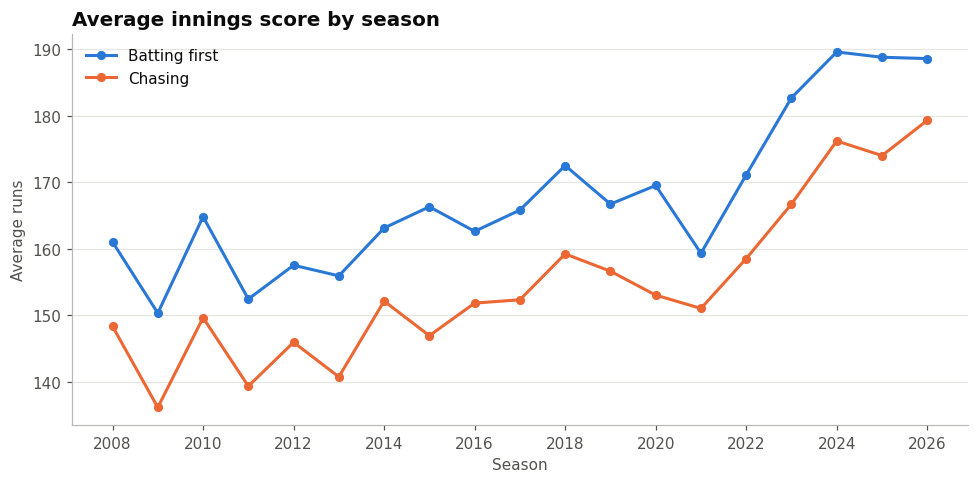

In [31]:
trend = matches.groupby("season_year")[["inn1_runs", "inn2_runs"]].mean().round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(trend.index, trend["inn1_runs"], color=BLUE, linewidth=2, marker="o", markersize=5, label="Batting first")
ax.plot(trend.index, trend["inn2_runs"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="Chasing")
ax.set_title("Average innings score by season")
ax.set_xlabel("Season")
ax.set_ylabel("Average runs")
ax.set_xticks(trend.index[::2])
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

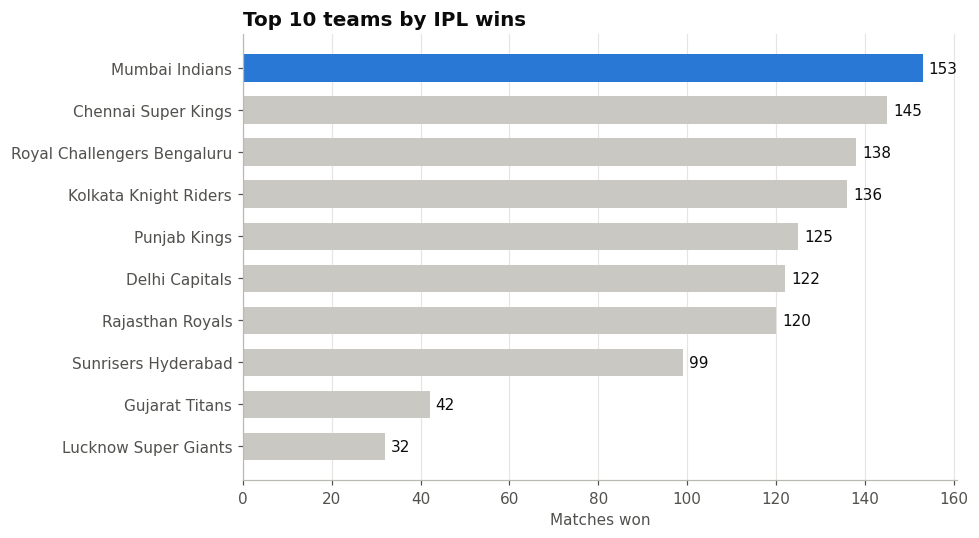

In [32]:
wins = matches[matches["decided"]].groupby("winner").size().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5))
colors = [BLUE] + [GRAY] * (len(wins) - 1)
bars = ax.barh(wins.index[::-1], wins.values[::-1], color=colors[::-1], height=0.65)
ax.bar_label(bars, padding=4, color=INK)
ax.set_title("Top 10 teams by IPL wins")
ax.set_xlabel("Matches won")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

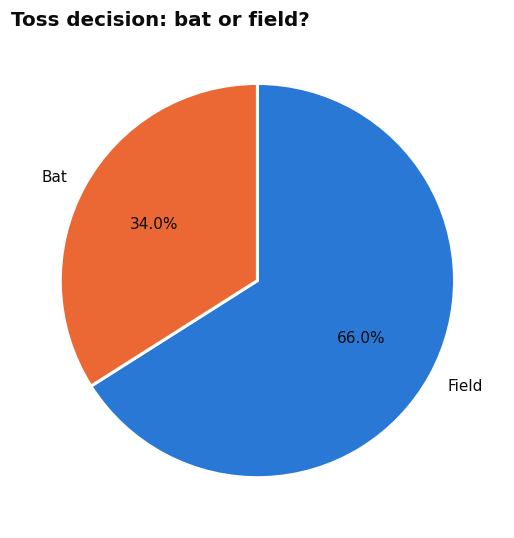

In [33]:
toss = matches["toss_decision"].value_counts()

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(toss.values, labels=[k.title() for k in toss.index], colors=[BLUE, ORANGE],
       autopct="%1.1f%%", startangle=90, counterclock=False,
       wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": INK})
ax.set_title("Toss decision: bat or field?")
fig.tight_layout()
plt.show()

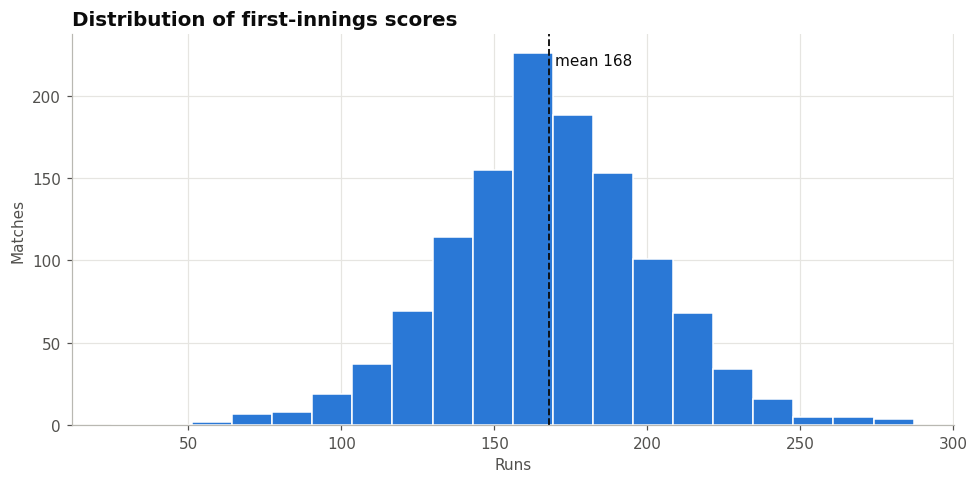

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(matches["inn1_runs"], bins=20, color=BLUE, edgecolor="white", linewidth=1)

m = matches["inn1_runs"].mean()
ax.axvline(m, color=INK, linestyle="--", linewidth=1.2)
ax.text(m + 2, ax.get_ylim()[1] * 0.92, f"mean {m:.0f}", color=INK)

ax.set_title("Distribution of first-innings scores")
ax.set_xlabel("Runs")
ax.set_ylabel("Matches")
fig.tight_layout()
plt.show()

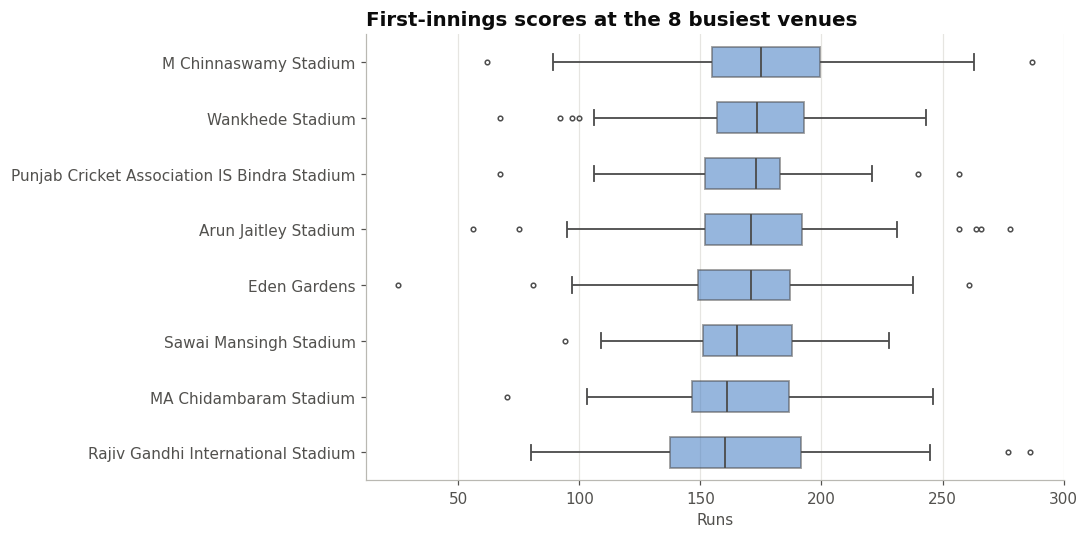

In [35]:
top_venues = matches["venue"].value_counts().head(8).index
vdata = matches[matches["venue"].isin(top_venues)]
order = vdata.groupby("venue")["inn1_runs"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=vdata, y="venue", x="inn1_runs", order=order, color=BLUE,
            width=0.55, linewidth=1.2, fliersize=3, ax=ax)
for patch in ax.patches:
    patch.set_alpha(0.55)
ax.set_title("First-innings scores at the 8 busiest venues")
ax.set_xlabel("Runs")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

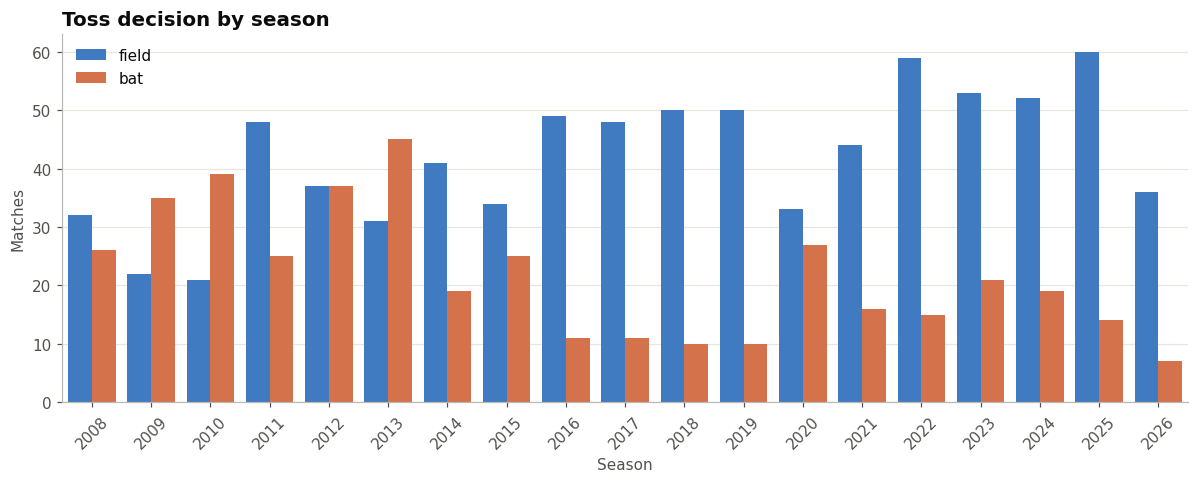

In [36]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.countplot(data=matches, x="season_year", hue="toss_decision",
              hue_order=["field", "bat"], palette={"field": BLUE, "bat": ORANGE}, ax=ax)
ax.set_title("Toss decision by season")
ax.set_xlabel("Season")
ax.set_ylabel("Matches")
ax.legend(title="", frameon=False, loc="upper left")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

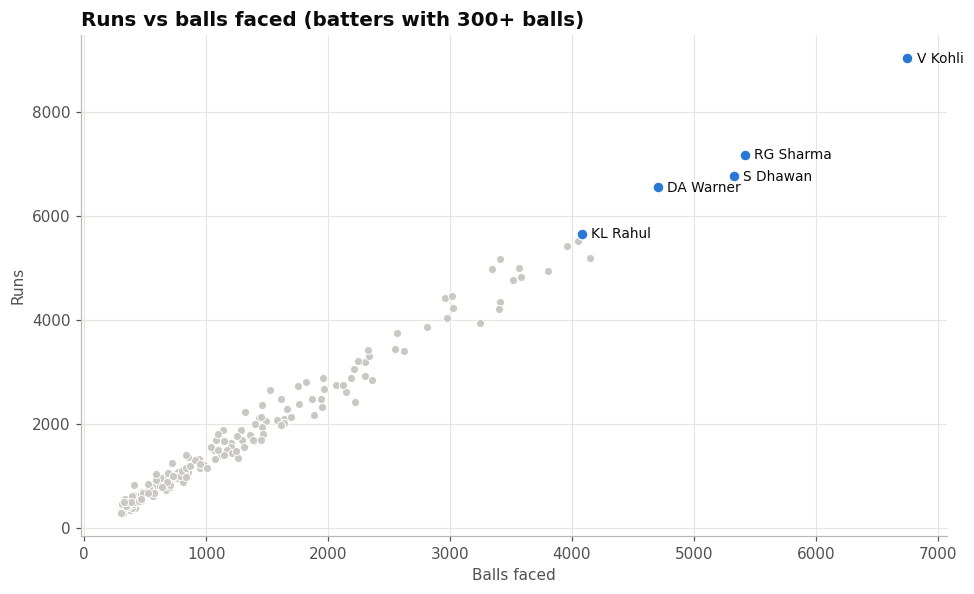

In [37]:
faced = deliveries[deliveries["wides"] == 0]
bat = faced.groupby("batter").agg(runs=("batter_runs", "sum"), balls=("batter_runs", "size"))
bat = bat[bat["balls"] >= 300].reset_index()
top5 = bat.nlargest(5, "runs")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=bat, x="balls", y="runs", color=GRAY, s=28, edgecolor="white", linewidth=0.6, ax=ax)
sns.scatterplot(data=top5, x="balls", y="runs", color=BLUE, s=50, edgecolor="white", linewidth=0.8, ax=ax)
for _, r in top5.iterrows():
    ax.annotate(r["batter"], (r["balls"], r["runs"]), textcoords="offset points", xytext=(6, -3), color=INK, fontsize=9)
ax.set_title("Runs vs balls faced (batters with 300+ balls)")
ax.set_xlabel("Balls faced")
ax.set_ylabel("Runs")
fig.tight_layout()
plt.show()

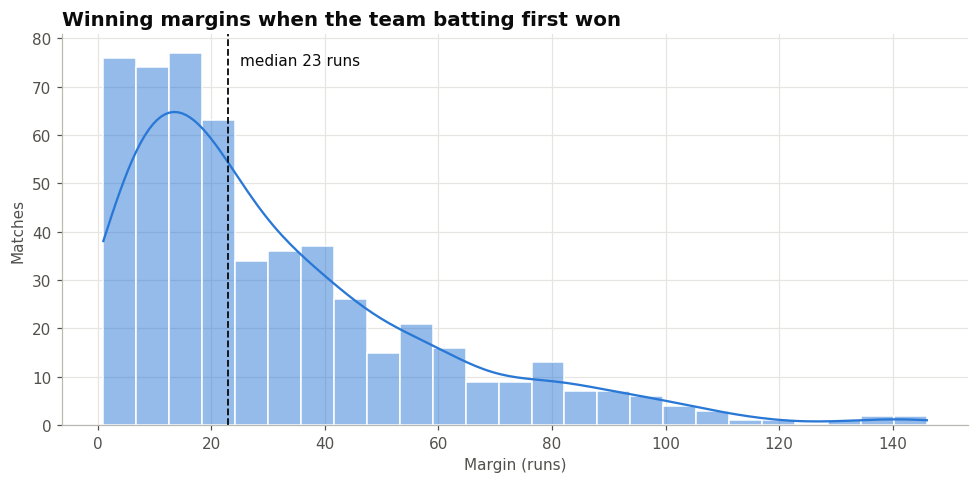

In [38]:
runs_wins = matches[matches["margin_type"] == "runs"]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=runs_wins, x="margin", bins=25, kde=True, color=BLUE,
             edgecolor="white", linewidth=1, ax=ax)
med = runs_wins["margin"].median()
ax.axvline(med, color=INK, linestyle="--", linewidth=1.2)
ax.text(med + 2, ax.get_ylim()[1] * 0.92, f"median {med:.0f} runs", color=INK)
ax.set_title("Winning margins when the team batting first won")
ax.set_xlabel("Margin (runs)")
ax.set_ylabel("Matches")
fig.tight_layout()
plt.show()

In [39]:
import difflib

# Helper columns on regular-innings deliveries (innings 1 and 2)
reg = deliveries[deliveries["innings"].isin([1, 2])].copy()
reg["is_faced"] = (reg["wides"] == 0).astype(int)
reg["is_four"] = (reg["batter_runs"] == 4).astype(int)
reg["is_six"] = (reg["batter_runs"] == 6).astype(int)
reg["is_single"] = (reg["batter_runs"] == 1).astype(int)
reg["bowler_runs"] = reg["batter_runs"] + reg["wides"] + reg["noballs"]
not_bowler = ["run out", "retired hurt", "retired out", "obstructing the field", "not out"]
reg["bowler_wicket"] = ((reg["is_wicket"] == 1) & ~reg["wicket_kind"].isin(not_bowler)).astype(int)

# Table 1: one row per batter per innings
batter_inn = reg.groupby(["match_id", "innings", "batter"]).agg(
    season_year=("season_year", "first"),
    runs=("batter_runs", "sum"), balls=("is_faced", "sum"),
    fours=("is_four", "sum"), sixes=("is_six", "sum"), singles=("is_single", "sum"),
).reset_index()
dismissed = (reg[reg["is_wicket"] == 1]
             .groupby(["match_id", "innings", "wicket_player_out"]).size()
             .rename("out").reset_index().rename(columns={"wicket_player_out": "batter"}))
batter_inn = batter_inn.merge(dismissed, on=["match_id", "innings", "batter"], how="left")
batter_inn["out"] = batter_inn["out"].fillna(0).clip(upper=1).astype(int)

# Table 2: one row per bowler per match
bowler_match = reg.groupby(["match_id", "bowler"]).agg(
    season_year=("season_year", "first"),
    balls=("is_legal_ball", "sum"), runs=("bowler_runs", "sum"), wickets=("bowler_wicket", "sum"),
).reset_index()
bowler_kinds = (reg[reg["bowler_wicket"] == 1].groupby(["bowler", "wicket_kind"]).size()
                .rename("count").reset_index())

# Table 3: one row per team innings
team_innings = inn.merge(matches[["match_id", "season_year"]], on="match_id")[
    ["match_id", "season_year", "innings", "batting_team", "runs", "wickets", "legal_balls"]]

print("batter_inn:", batter_inn.shape, "| bowler_match:", bowler_match.shape, "| team_innings:", team_innings.shape)

batter_inn: (18299, 10) | bowler_match: (14338, 6) | team_innings: (2418, 7)


In [40]:
from matplotlib.ticker import MaxNLocator

all_teams = sorted(set(matches["team1"]) | set(matches["team2"]))
AQUA, YELLOW = "#1baf7a", "#eda100"

def find_team(text):
    t = alias_map.get(text.strip().lower(), text.strip())
    lower = {x.lower(): x for x in all_teams}
    if t.lower() in lower:
        return lower[t.lower()]
    hits = [x for x in all_teams if t.lower() in x.lower()]
    if len(hits) == 1:
        return hits[0]
    close = difflib.get_close_matches(t, all_teams, n=3, cutoff=0.5)
    raise ValueError(f"Team not found: '{text}'. Did you mean: {', '.join(close or hits or all_teams[:5])}?")

def find_player(text, names):
    counts = names.value_counts()                      # appearances per player
    pool = pd.Series(counts.index)
    t = text.strip().lower()
    exact = pool[pool.str.lower() == t]
    if len(exact):
        return exact.iloc[0]
    hits = pool[pool.str.lower().str.contains(t, regex=False)]
    hits = hits.sort_values(key=lambda s: s.map(counts), ascending=False)
    if len(hits) == 1:
        return hits.iloc[0]
    if len(hits) > 1:
        if counts[hits.iloc[0]] >= 5 * counts[hits.iloc[1]]:      # one clear regular player
            return hits.iloc[0]
        raise ValueError(f"Several players match '{text}': {', '.join(hits.head(5))}. Type the full name.")
    close = difflib.get_close_matches(text.strip(), list(pool), n=3, cutoff=0.5)
    raise ValueError(f"Player not found: '{text}'. Did you mean: {', '.join(close) or 'no close match'}?")

def summary_table(d):
    return pd.DataFrame({"Metric": list(d.keys()), "Value": [str(v) for v in d.values()]})

def show_report(result):
    tables, figs = result
    for title, tbl in tables:
        print(f"\n--- {title} ---")
        display(tbl)
    for fig in figs:
        display(fig)

# ---------------- 1. TEAM REPORT ----------------
def team_report(team_text):
    team = find_team(team_text)
    m = matches[(matches["team1"] == team) | (matches["team2"] == team)]
    d = m[m["decided"]]
    wins = d[d["winner"] == team]
    toss_won = d[d["toss_winner"] == team]
    toss_conv = (toss_won["winner"] == team).mean() * 100
    best_venue = wins["venue"].value_counts().index[0] if len(wins) else "n/a"
    summary = summary_table({
        "Matches played": len(m), "Wins": len(wins), "Win %": round(len(wins) / len(d) * 100, 1),
        "Titles": int((season_df["champion"] == team).sum()),
        "Toss won -> match won %": round(toss_conv, 1), "Best venue (most wins)": best_venue})
    figs = []
    played = m.groupby("season_year").size()
    w = wins.groupby("season_year").size().reindex(played.index, fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(w.index, w.values, color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.set_title(f"{team}: wins per season"); ax.set_xlabel("Season"); ax.set_ylabel("Wins")
    ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)

    bat_first = int((wins["batting_first"] == team).sum())
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.pie([bat_first, len(wins) - bat_first], labels=["Batting first", "Chasing"], colors=[BLUE, ORANGE],
           autopct="%1.1f%%", startangle=90, counterclock=False,
           wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": INK})
    ax.set_title("How the wins came"); fig.tight_layout(); figs.append(fig)

    top_v = wins["venue"].value_counts().head(5)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    bars = ax.barh(top_v.index[::-1], top_v.values[::-1], color=BLUE, height=0.6)
    ax.bar_label(bars, padding=3, color=INK); ax.set_title("Top venues by wins"); ax.set_xlabel("Wins")
    ax.grid(axis="y", visible=False); fig.tight_layout(); figs.append(fig)

    ti = team_innings[team_innings["batting_team"] == team]
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(data=ti, x="season_year", y="runs", color=BLUE, width=0.6, linewidth=1, fliersize=3, ax=ax)
    for patch in ax.patches:
        patch.set_alpha(0.55)
    ax.set_title("Innings scores by season"); ax.set_xlabel("Season"); ax.set_ylabel("Runs")
    ax.tick_params(axis="x", rotation=45); ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Team report: {team}", summary)], figs

# ---------------- 2. SEASON REPORT ----------------
def season_report(year):
    year = int(year)
    m = matches[matches["season_year"] == year]
    if m.empty:
        raise ValueError(f"No matches for {year}. Choose a year from {matches['season_year'].min()} to {matches['season_year'].max()}.")
    d = m[m["decided"]]
    champ = season_df.loc[season_df["season"] == year, "champion"]
    champ = champ.iloc[0] if len(champ) else "Not recorded (season in progress)"
    top_bat = batter_inn[batter_inn["season_year"] == year].groupby("batter")["runs"].sum().nlargest(1)
    top_bowl = bowler_match[bowler_match["season_year"] == year].groupby("bowler")["wickets"].sum().nlargest(1)
    summary = summary_table({
        "Matches": len(m), "Champion": champ,
        "Most runs": f"{top_bat.index[0]} ({top_bat.iloc[0]})",
        "Most wickets": f"{top_bowl.index[0]} ({top_bowl.iloc[0]})",
        "Average first-innings score": round(m["inn1_runs"].mean(), 1),
        "Highest total": int(m["inn1_runs"].max())})
    wins_tbl = d.groupby("winner").agg(wins=("match_id", "count")).sort_values("wins", ascending=False).reset_index()
    figs = []
    colors = [BLUE if t == champ else GRAY for t in wins_tbl["winner"]]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(wins_tbl["winner"][::-1], wins_tbl["wins"][::-1], color=colors[::-1], height=0.65)
    ax.bar_label(bars, padding=3, color=INK); ax.set_title(f"{year}: wins per team (champion in blue)")
    ax.set_xlabel("Wins"); ax.grid(axis="y", visible=False); fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(team_innings[team_innings["season_year"] == year]["runs"], bins=15, color=BLUE, edgecolor="white", linewidth=1)
    ax.set_title(f"{year}: distribution of innings scores"); ax.set_xlabel("Runs"); ax.set_ylabel("Innings")
    fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.countplot(data=m, x="toss_decision", order=["field", "bat"], hue="toss_decision",
                  palette={"field": BLUE, "bat": ORANGE}, legend=False, ax=ax)
    ax.set_title(f"{year}: toss decisions"); ax.set_xlabel(""); ax.set_ylabel("Matches")
    ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Season report: {year}", summary), ("Wins per team", wins_tbl)], figs

# ---------------- 3. BATTER REPORT ----------------
def batter_report(name, from_year=None, to_year=None):
    player = find_player(name, batter_inn["batter"])
    b = batter_inn[batter_inn["batter"] == player]
    if from_year:
        b = b[b["season_year"] >= int(from_year)]
    if to_year:
        b = b[b["season_year"] <= int(to_year)]
    if b.empty:
        raise ValueError(f"{player} has no innings in that year range.")
    runs, balls, outs = b["runs"].sum(), b["balls"].sum(), b["out"].sum()
    summary = summary_table({
        "Matches": b["match_id"].nunique(), "Innings": len(b), "Runs": runs, "Balls faced": balls,
        "Strike rate": round(runs / balls * 100, 2),
        "Average": round(runs / outs, 2) if outs else "n/a (never dismissed)",
        "Highest score": int(b["runs"].max()),
        "50s": int(((b["runs"] >= 50) & (b["runs"] < 100)).sum()), "100s": int((b["runs"] >= 100).sum()),
        "Fours": int(b["fours"].sum()), "Sixes": int(b["sixes"].sum())})
    figs = []
    per_season = b.groupby("season_year")["runs"].sum()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(per_season.index, per_season.values, color=BLUE, linewidth=2, marker="o", markersize=5)
    ax.set_title(f"{player}: runs per season"); ax.set_xlabel("Season"); ax.set_ylabel("Runs")
    ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)

    singles, fours, sixes = b["singles"].sum(), b["fours"].sum() * 4, b["sixes"].sum() * 6
    others = max(runs - singles - fours - sixes, 0)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.pie([singles, others, fours, sixes], labels=["Singles", "2s, 3s & other", "Fours", "Sixes"],
           colors=[BLUE, ORANGE, AQUA, YELLOW], autopct="%1.0f%%", startangle=90, counterclock=False,
           wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": INK})
    ax.set_title("Where the runs come from"); fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.scatterplot(data=b, x="balls", y="runs", color=BLUE, s=35, edgecolor="white", linewidth=0.6, ax=ax)
    ax.set_title("Runs vs balls faced (each dot = one innings)"); ax.set_xlabel("Balls faced"); ax.set_ylabel("Runs")
    fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(data=b, x="runs", bins=12, kde=len(b) >= 10, color=BLUE, edgecolor="white", linewidth=1, ax=ax)
    ax.set_title("Distribution of innings scores"); ax.set_xlabel("Runs in an innings"); ax.set_ylabel("Innings")
    fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Batter report: {player}", summary)], figs

# ---------------- 4. BOWLER REPORT ----------------
def bowler_report(name):
    player = find_player(name, bowler_match["bowler"])
    w = bowler_match[bowler_match["bowler"] == player]
    wickets, balls, runs = w["wickets"].sum(), w["balls"].sum(), w["runs"].sum()
    best = w.sort_values(["wickets", "runs"], ascending=[False, True]).iloc[0]
    summary = summary_table({
        "Matches": len(w), "Wickets": wickets, "Overs bowled": f"{balls // 6}.{balls % 6}",
        "Runs conceded": runs, "Economy": round(runs / (balls / 6), 2),
        "Average": round(runs / wickets, 2) if wickets else "n/a",
        "Strike rate (balls/wkt)": round(balls / wickets, 1) if wickets else "n/a",
        "Best figures": f"{int(best['wickets'])}/{int(best['runs'])}"})
    figs = []
    per_season = w.groupby("season_year")["wickets"].sum()
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(per_season.index, per_season.values, color=BLUE, width=0.6)
    ax.set_title(f"{player}: wickets per season"); ax.set_xlabel("Season"); ax.set_ylabel("Wickets")
    ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)

    kinds = bowler_kinds[bowler_kinds["bowler"] == player].set_index("wicket_kind")["count"].sort_values(ascending=False)
    if len(kinds) > 3:
        kinds = pd.concat([kinds.head(3), pd.Series({"other": kinds.iloc[3:].sum()})])
    if kinds.sum() > 0:
        fig, ax = plt.subplots(figsize=(5, 4.5))
        ax.pie(kinds.values, labels=kinds.index, colors=[BLUE, ORANGE, AQUA, GRAY][:len(kinds)],
               autopct="%1.0f%%", startangle=90, counterclock=False,
               wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": INK})
        ax.set_title("How the wickets came"); fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(8, 3))
    sns.boxplot(x=w["runs"], color=BLUE, width=0.4, linewidth=1.2, fliersize=3, ax=ax)
    for patch in ax.patches:
        patch.set_alpha(0.55)
    ax.set_title("Runs conceded per match"); ax.set_xlabel("Runs"); ax.grid(axis="y", visible=False)
    fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Bowler report: {player}", summary)], figs



In [41]:
# ---------------- 5. HEAD TO HEAD ----------------
def head_to_head(team_a, team_b):
    A, B = find_team(team_a), find_team(team_b)
    if A == B:
        raise ValueError("Please enter two different teams.")
    m = matches[((matches["team1"] == A) & (matches["team2"] == B)) |
                ((matches["team1"] == B) & (matches["team2"] == A))].sort_values("date")
    if m.empty:
        raise ValueError(f"{A} and {B} have never played each other in this data.")
    wa, wb, nr = int((m["winner"] == A).sum()), int((m["winner"] == B).sum()), int((~m["decided"]).sum())
    summary = summary_table({"Meetings": len(m), f"{A} wins": wa, f"{B} wins": wb, "No result / tie": nr})
    last5 = m.tail(5).iloc[::-1][["date", "venue", "winner", "margin", "margin_type"]].copy()
    last5["date"] = last5["date"].dt.date
    figs = []
    labels, vals, cols = [A, B], [wa, wb], [BLUE, ORANGE]
    if nr:
        labels.append("No result"); vals.append(nr); cols.append(GRAY)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.pie(vals, labels=labels, colors=cols, autopct="%1.0f%%", startangle=90, counterclock=False,
           wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": INK})
    ax.set_title("Win split"); fig.tight_layout(); figs.append(fig)

    years = sorted(m["season_year"].unique())
    fig, ax = plt.subplots(figsize=(8, 4))
    for team, col in [(A, BLUE), (B, ORANGE)]:
        s = m[m["winner"] == team].groupby("season_year").size().reindex(years, fill_value=0)
        ax.plot(s.index, s.values, color=col, linewidth=2, marker="o", markersize=5, label=team)
    ax.set_title("Wins in this fixture by year"); ax.set_xlabel("Season"); ax.set_ylabel("Wins")
    ax.set_xticks(years); ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(frameon=False); ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)

    ti = team_innings[team_innings["match_id"].isin(m["match_id"]) & team_innings["batting_team"].isin([A, B])]
    avg = ti.groupby("batting_team")["runs"].mean().reindex([A, B]).round(1)
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(avg.index, avg.values, color=[BLUE, ORANGE], width=0.5)
    ax.bar_label(bars, padding=3, color=INK); ax.set_title("Average innings score in this fixture")
    ax.set_ylabel("Runs"); ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Head-to-head: {A} vs {B}", summary), ("Last 5 meetings (newest first)", last5)], figs

# ---------------- 6. VENUE REPORT ----------------
def venue_report(text):
    t = text.strip().lower()
    mask = matches["venue"].str.lower().str.contains(t, regex=False) | matches["city"].str.lower().str.contains(t, regex=False)
    m = matches[mask]
    if m.empty:
        pool = sorted(set(matches["venue"]) | set(matches["city"]))
        close = difflib.get_close_matches(text.strip(), pool, n=3, cutoff=0.4)
        raise ValueError(f"Venue or city not found: '{text}'. Did you mean: {', '.join(close) or 'no close match'}?")
    d = m[m["decided"]]
    summary = summary_table({
        "Grounds matched": ", ".join(sorted(m["venue"].unique())), "Matches hosted": len(m),
        "Average first-innings score": round(m["inn1_runs"].mean(), 1),
        "Highest total": int(m["inn1_runs"].max()),
        "Chasing win %": round(d["chasing_win"].mean() * 100, 1),
        "Toss winners who chose to field %": round((m["toss_decision"] == "field").mean() * 100, 1)})
    figs = []
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(m["inn1_runs"], bins=15, color=BLUE, edgecolor="white", linewidth=1)
    ax.set_title("First-innings scores here"); ax.set_xlabel("Runs"); ax.set_ylabel("Matches")
    fig.tight_layout(); figs.append(fig)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.countplot(data=m, x="toss_decision", order=["field", "bat"], hue="toss_decision",
                  palette={"field": BLUE, "bat": ORANGE}, legend=False, ax=ax)
    ax.set_title("Toss decisions here"); ax.set_xlabel(""); ax.set_ylabel("Matches")
    ax.grid(axis="x", visible=False); fig.tight_layout(); figs.append(fig)

    top_t = d["winner"].value_counts().head(5)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    bars = ax.barh(top_t.index[::-1], top_t.values[::-1], color=BLUE, height=0.6)
    ax.bar_label(bars, padding=3, color=INK); ax.set_title("Most wins at this venue"); ax.set_xlabel("Wins")
    ax.grid(axis="y", visible=False); fig.tight_layout(); figs.append(fig)
    for f in figs:
        plt.close(f)
    return [(f"Venue report: {text}", summary)], figs


--- Team report: Mumbai Indians ---


,Metric,Value
0,Matches played,285
1,Wins,153
2,Win %,54.4
3,Titles,5
4,Toss won -> match won %,54.2
5,Best venue (most wins),Wankhede Stadium


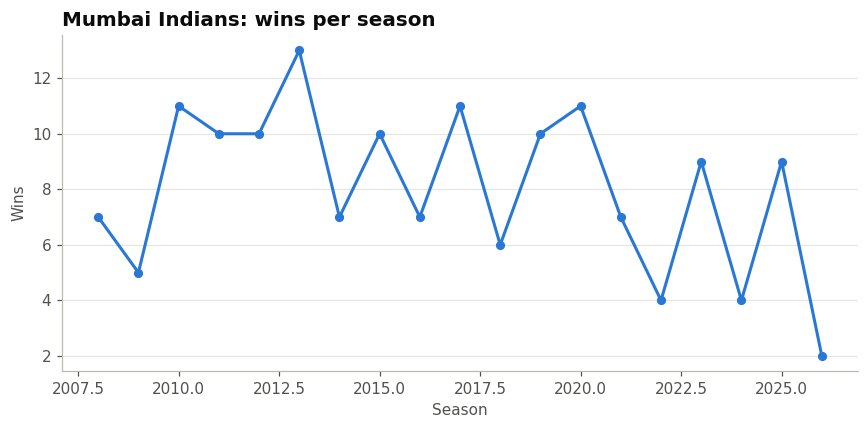

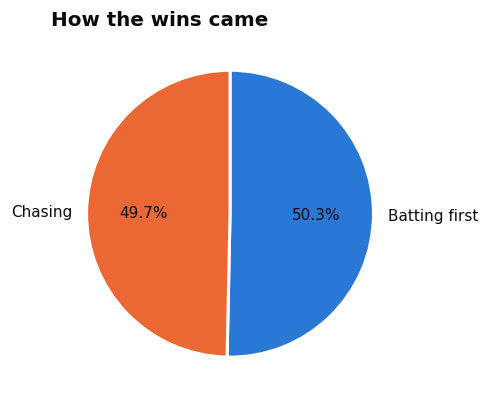

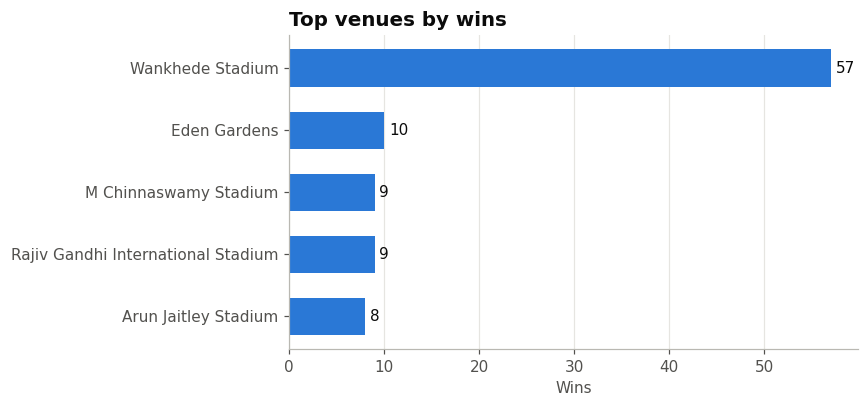

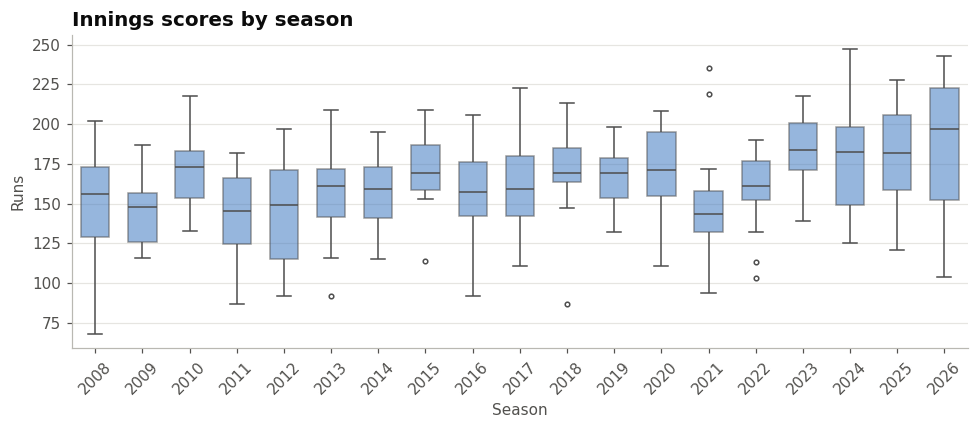


--- Season report: 2016 ---


,Metric,Value
0,Matches,60
1,Champion,Sunrisers Hyderabad
2,Most runs,V Kohli (973)
3,Most wickets,B Kumar (23)
4,Average first-innings score,162.6
5,Highest total,248



--- Wins per team ---


,winner,wins
0,Sunrisers Hyderabad,11
1,Gujarat Lions,9
2,Royal Challengers Bengaluru,9
3,Kolkata Knight Riders,8
4,Mumbai Indians,7
5,Delhi Capitals,7
6,Rising Pune Supergiant,5
7,Punjab Kings,4


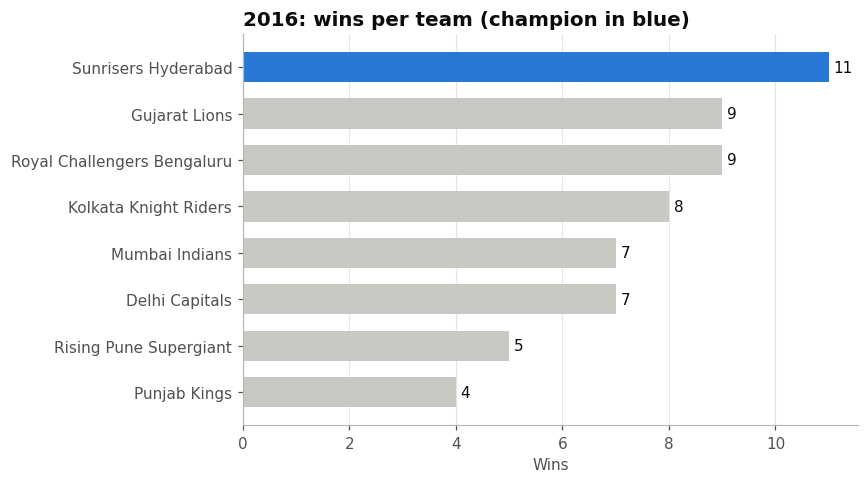

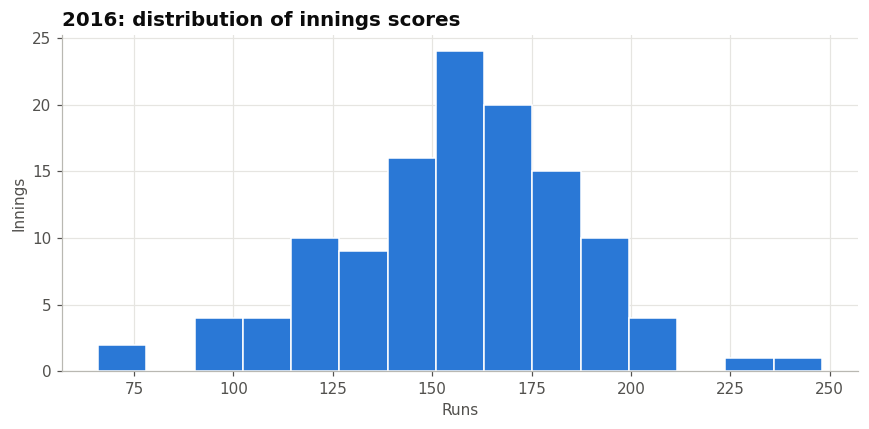

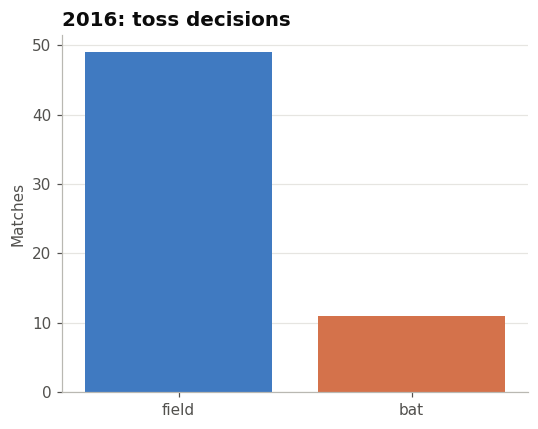


--- Batter report: V Kohli ---


,Metric,Value
0,Matches,268
1,Innings,268
2,Runs,9040
3,Balls faced,6748
4,Strike rate,133.97
5,Average,40.0
6,Highest score,113
7,50s,66
8,100s,8
9,Fours,814


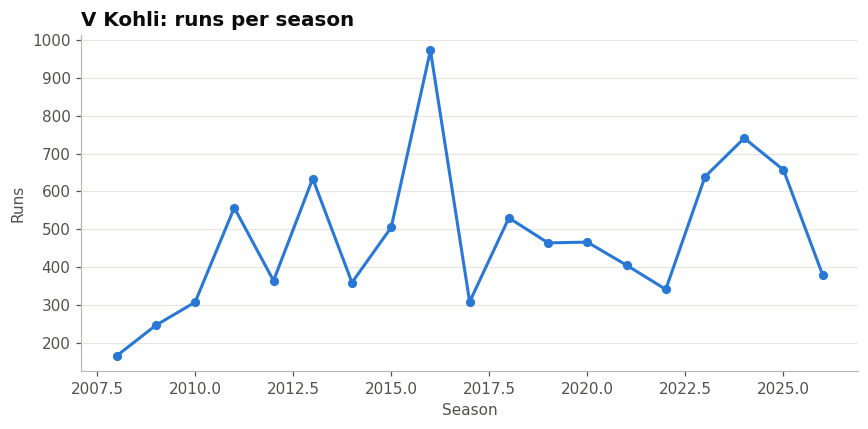

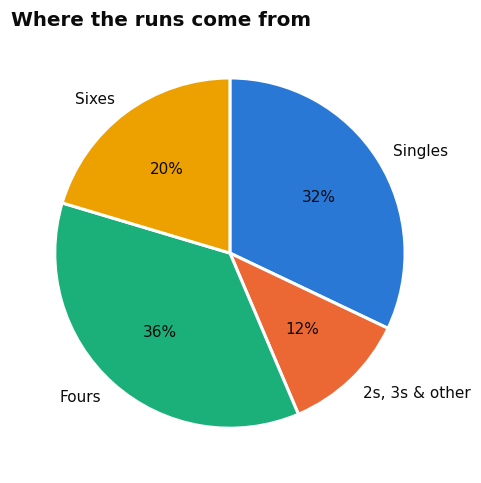

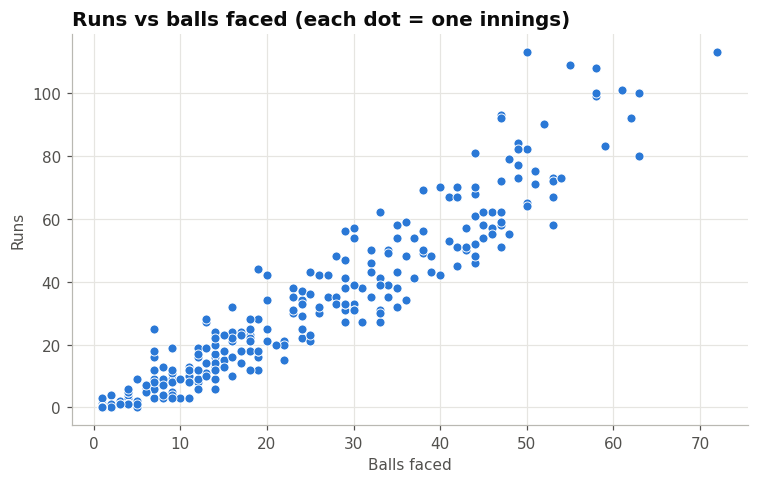

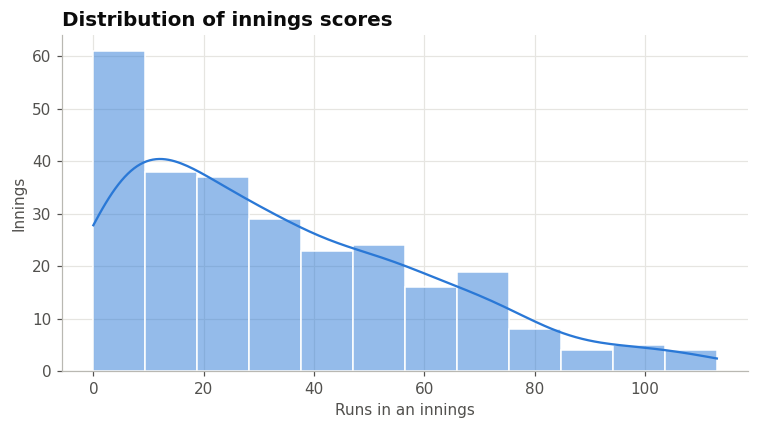


--- Bowler report: JJ Bumrah ---


,Metric,Value
0,Matches,153
1,Wickets,185
2,Overs bowled,586.1
3,Runs conceded,4295
4,Economy,7.33
5,Average,23.22
6,Strike rate (balls/wkt),19.0
7,Best figures,5/10


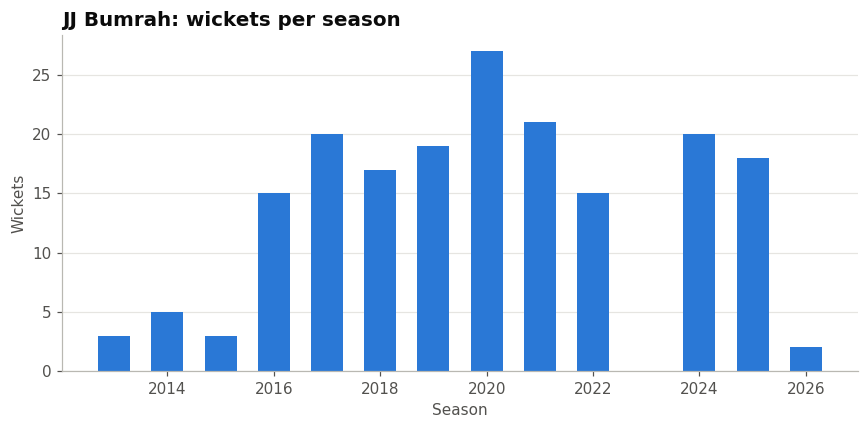

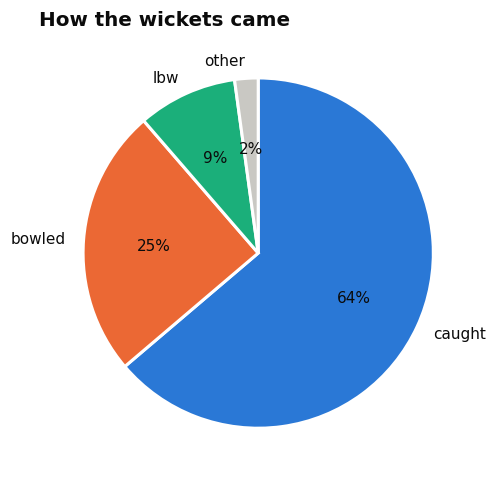

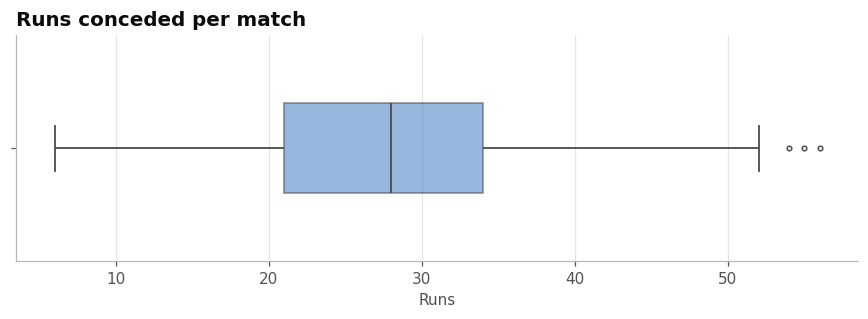


--- Head-to-head: Chennai Super Kings vs Mumbai Indians ---


,Metric,Value
0,Meetings,40
1,Chennai Super Kings wins,19
2,Mumbai Indians wins,21
3,No result / tie,0



--- Last 5 meetings (newest first) ---


,date,venue,winner,margin,margin_type
624,2026-04-23,Wankhede Stadium,Chennai Super Kings,103.0,runs
555,2025-04-20,Wankhede Stadium,Mumbai Indians,9.0,wickets
520,2025-03-23,MA Chidambaram Stadium,Chennai Super Kings,4.0,wickets
475,2024-04-14,Wankhede Stadium,Chennai Super Kings,20.0,runs
421,2023-05-06,MA Chidambaram Stadium,Chennai Super Kings,6.0,wickets


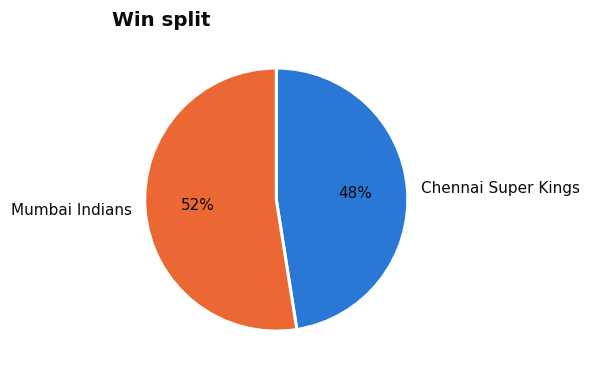

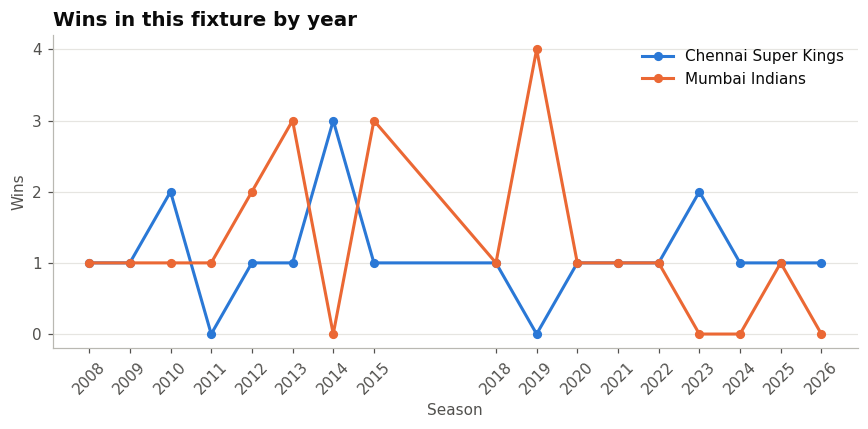

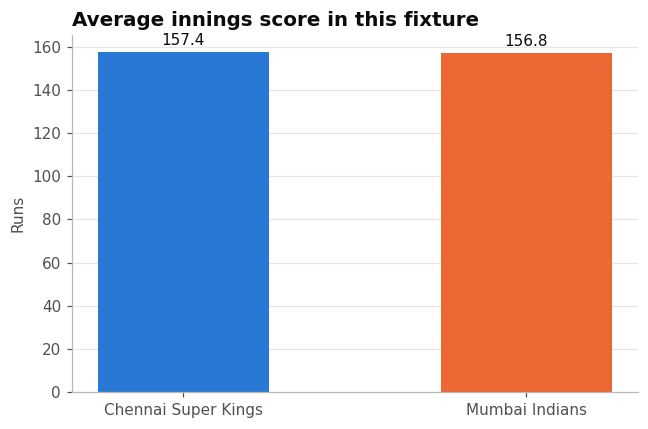


--- Venue report: wankhede ---


,Metric,Value
0,Grounds matched,Wankhede Stadium
1,Matches hosted,130
2,Average first-innings score,172.5
3,Highest total,243
4,Chasing win %,55.0
5,Toss winners who chose to field %,76.2


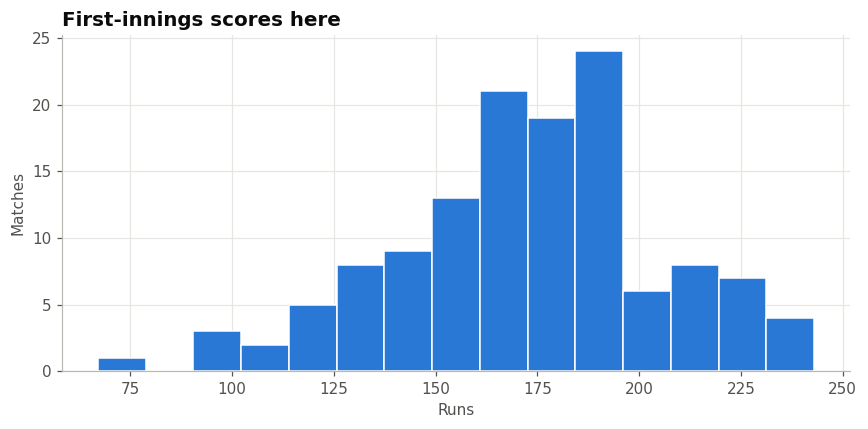

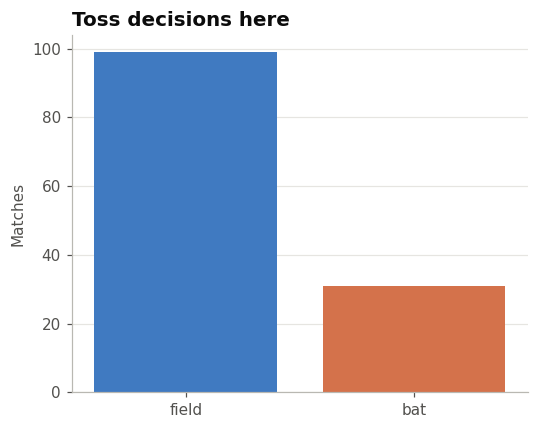

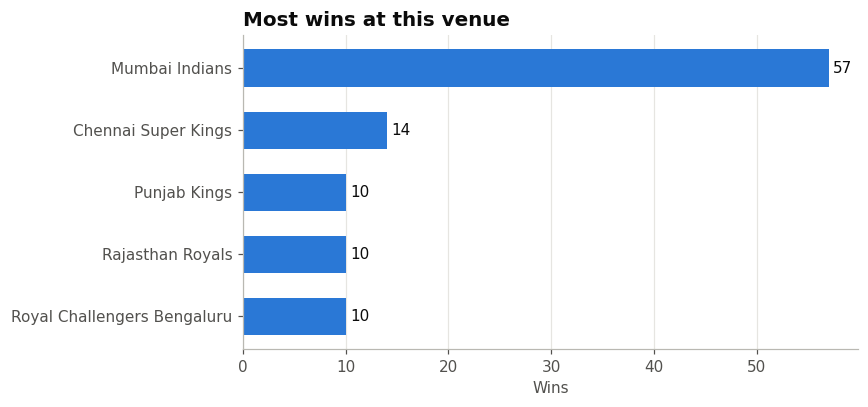

Team not found: 'xyz'. Did you mean: Chennai Super Kings, Deccan Chargers, Delhi Capitals, Gujarat Lions, Gujarat Titans?


In [42]:
show_report(team_report("mi"))
show_report(season_report(2016))
show_report(batter_report("kohli"))
show_report(bowler_report("bumrah"))
show_report(head_to_head("csk", "mi"))
show_report(venue_report("wankhede"))

# Bad input should give a friendly message, not a crash
try:
    show_report(team_report("xyz"))
except ValueError as e:
    print(e)

In [43]:
MENU = """
=========== IPL EXPLORER ===========
1. Team Report
2. Season Report
3. Batter Report
4. Bowler Report
5. Head-to-Head (Team vs Team)
6. Venue Report
7. Exit
"""

def ask(prompt):
    return input(prompt).strip()

def ask_year(prompt):
    text = ask(prompt)
    if text == "":
        return None
    if not text.isdigit():
        raise ValueError(f"'{text}' is not a valid year. Type a number like 2019, or press Enter to skip.")
    return int(text)

def ipl_explorer():
    while True:
        print(MENU)
        choice = ask("Enter your choice (1-7): ")
        try:
            if choice == "1":
                show_report(team_report(ask("Enter team name (e.g. MI, CSK, RCB): ")))
            elif choice == "2":
                year = ask_year("Enter season year (2008-2026): ")
                if year is None:
                    raise ValueError("Please type a year.")
                show_report(season_report(year))
            elif choice == "3":
                name = ask("Enter batter name (e.g. kohli): ")
                from_year = ask_year("From year (press Enter to skip): ")
                to_year = ask_year("To year (press Enter to skip): ")
                show_report(batter_report(name, from_year, to_year))
            elif choice == "4":
                show_report(bowler_report(ask("Enter bowler name (e.g. bumrah): ")))
            elif choice == "5":
                a = ask("Enter first team: ")
                b = ask("Enter second team: ")
                show_report(head_to_head(a, b))
            elif choice == "6":
                show_report(venue_report(ask("Enter venue or city (e.g. wankhede, chennai): ")))
            elif choice == "7":
                print("Goodbye!")
                break
            else:
                print("Please enter a number from 1 to 7.")
        except ValueError as e:
            print("\n", e)

ipl_explorer()


=========== IPL EXPLORER ===========
1. Team Report
2. Season Report
3. Batter Report
4. Bowler Report
5. Head-to-Head (Team vs Team)
6. Venue Report
7. Exit

Enter your choice (1-7): 7
Goodbye!


In [44]:
d = matches[matches["decided"]].copy()
d["period"] = pd.cut(d["season_year"], [2007, 2012, 2017, 2022, 2026],
                     labels=["2008-12", "2013-17", "2018-22", "2023-26"])

toss_rate = d["toss_win_match_win"].mean() * 100
by_dec = d.groupby("toss_decision", observed=True)["toss_win_match_win"].mean() * 100
chase_rate = d["chasing_win"].mean() * 100
field_share = d.groupby("period", observed=True)["toss_decision"].apply(lambda s: (s == "field").mean() * 100)
avg_first = matches.groupby("season_year")["inn1_runs"].mean()
big = matches[matches["inn1_runs"] >= 200].groupby("season_year").size()
vs = d.groupby("venue").agg(n=("match_id", "count"), chase=("chasing_win", "mean"), avg=("inn1_runs", "mean"))
vs = vs[vs["n"] >= 30]
best_chase, worst_chase, high_venue = vs["chase"].idxmax(), vs["chase"].idxmin(), vs["avg"].idxmax()
wins = d.groupby("winner").size().sort_values(ascending=False)

print("KEY INSIGHTS (all computed from the data)\n")
print(f"1. Toss: toss winners won {toss_rate:.1f}% of {len(d)} decided matches, a small edge. "
      f"Choosing to field won {by_dec['field']:.1f}% versus {by_dec['bat']:.1f}% for choosing to bat.")
print(f"2. Scoring: the average first-innings score rose from {avg_first[2008]:.0f} in 2008 to {avg_first[2024]:.0f} in 2024, "
      f"and 200+ totals went from {big.get(2022, 0)} in 2022 to {big.get(2025, 0)} in 2025.")
print(f"3. Strategy shift: captains who won the toss chose to field {field_share['2008-12']:.0f}% of the time in 2008-12, "
      f"rising to {field_share['2023-26']:.0f}% in 2023-26.")
print(f"4. Chasing: chasing teams won {chase_rate:.1f}% overall. It depends on the ground: "
      f"{best_chase} {vs.loc[best_chase, 'chase']*100:.0f}% vs {worst_chase} {vs.loc[worst_chase, 'chase']*100:.0f}%. "
      f"Highest-scoring venue: {high_venue} ({vs.loc[high_venue, 'avg']:.0f} average first innings).")
print(f"5. Teams: {wins.index[0]} lead with {wins.iloc[0]} wins, then {wins.index[1]} ({wins.iloc[1]}) and {wins.index[2]} ({wins.iloc[2]}).")
print("\nNote: 2026 is a partial season, so recent-period figures may still change.")

KEY INSIGHTS (all computed from the data)

1. Toss: toss winners won 51.6% of 1187 decided matches, a small edge. Choosing to field won 54.6% versus 45.8% for choosing to bat.
2. Scoring: the average first-innings score rose from 161 in 2008 to 190 in 2024, and 200+ totals went from 13 in 2022 to 33 in 2025.
3. Strategy shift: captains who won the toss chose to field 50% of the time in 2008-12, rising to 77% in 2023-26.
4. Chasing: chasing teams won 54.5% overall. It depends on the ground: Sawai Mansingh Stadium 65% vs MA Chidambaram Stadium 45%. Highest-scoring venue: Narendra Modi Stadium (181 average first innings).
5. Teams: Mumbai Indians lead with 153 wins, then Chennai Super Kings (145) and Royal Challengers Bengaluru (138).

Note: 2026 is a partial season, so recent-period figures may still change.


In [45]:
import os, shutil

os.makedirs("app_data", exist_ok=True)
matches.to_csv("app_data/matches.csv", index=False)
team_innings.to_csv("app_data/team_innings.csv", index=False)
batter_inn.to_csv("app_data/batter_inn.csv", index=False)
bowler_match.to_csv("app_data/bowler_match.csv", index=False)
bowler_kinds.to_csv("app_data/bowler_kinds.csv", index=False)
season_df.to_csv("app_data/season_df.csv", index=False)
shutil.copy("data/team_aliases.txt", "app_data/team_aliases.txt")
shutil.make_archive("app_data", "zip", "app_data")

for f in sorted(os.listdir("app_data")):
    print(f"{f}: {os.path.getsize('app_data/'+f)/1e6:.2f} MB")
print("zip:", round(os.path.getsize("app_data.zip") / 1e6, 2), "MB")

batter_inn.csv: 0.70 MB
bowler_kinds.csv: 0.03 MB
bowler_match.csv: 0.45 MB
matches.csv: 0.46 MB
season_df.csv: 0.00 MB
team_aliases.txt: 0.00 MB
team_innings.csv: 0.10 MB
zip: 0.33 MB


In [46]:
from google.colab import files
files.download("app_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>